---
## Task 2- Content Type Analysis Dashboard
---

### Loading the dataset

In [6]:
import pandas as pd
df = pd.read_csv('cleaned_dataset.csv')
df.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in,duration_value,duration_unit
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries,90,min
1,s3,Tv Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",1,Season
2,s6,Tv Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries",1,Season
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies",91,min
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies",125,min


### Calculating the total number of Movies and TV Shows

In [7]:
#Counting the total occurrences of each
type_counts = df['type'].value_counts()
#Displaying results
print(type_counts)

type
Movie      6126
Tv Show    2664
Name: count, dtype: int64


From this output, **Movies dominate Netflix's content library**, making up roughly 69.7% of all titles while TV Shows accoount for 30.3%.

### Creating Visualisations for Content Distribution

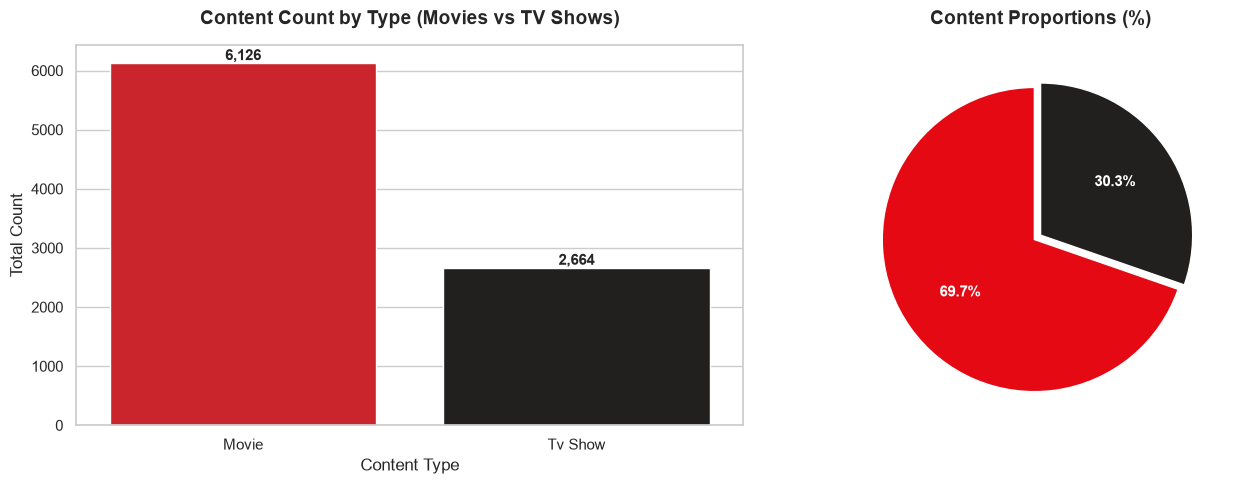

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

#Setting figure and style
plt.figure(figsize=(14,5))
sns.set_theme(style='whitegrid')

#Color Palette
colors = ['#E50914', '#221F1F'] # Netflix Red and Dark Slate

#Bar Chart
plt.subplot(1,2,1)
ax = sns.barplot(
    x=type_counts.index,
    y=type_counts.values,
    hue=type_counts.index,
    palette=colors,
    legend=False
)
plt.title('Content Count by Type (Movies vs TV Shows)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Content Type', fontsize=12)
plt.ylabel('Total Count', fontsize=12)

#Adding numerical value labels on top of each bar
for p in ax.patches:
  ax.annotate(f'{int(p.get_height()):,}',
              (p.get_x() + p.get_width() / 2., p.get_height()),
              ha='center', va='center',
              fontsize=11, fontweight='bold',
              xytext=(0, 5), textcoords='offset points')

#Pie Chart
plt.subplot(1,2,2)
plt.pie(type_counts.values,
        labels=type_counts.index,
        autopct='%1.1f%%',
        startangle=90,
        colors=colors,
        explode=(0.05, 0),
        textprops={'fontsize': 11, 'weight': 'bold', 'color': 'white'})
plt.title('Content Proportions (%)', fontsize=14, fontweight='bold', pad=15)

#Displaying Charts
plt.tight_layout()
plt.show()

### Comparing Content Proportions


In [4]:
#Calculating Percentage Distribution
type_percentages = (df['type'].value_counts(normalize=True) * 100).round(2)

#Displaying output as a DataFrame
df_proportions = pd.DataFrame({'Count': type_counts, 'Percentage (%)' : type_percentages})

display(df_proportions)

,Count,Percentage (%)
type,,
Movie,6126,69.69
Tv Show,2664,30.31


### Key Findings


*   **Movie Dominance** - Movies make up roughly 70% of Netflix's entire catalog, outnumbering TV Shows by more than a 2:1 ratio.
*   **Library Composition** - While Netflix started primarily as a film licensing platform, TV Shows account for 30% of the total catalog, representing a significant investment in episodic and multi-season content.

